# Geo-Miner live demo: WoE baseline vs small U-Net
1. **Add Input**: a dataset containing the Stream_Sediments KMZ and Minerals_Kar KML.
2. Run cells top to bottom (cells 1-4 write the scripts, cell 5 finds the data).
3. The results cells draw the tables, ROC curves, confusion matrices and maps.

In [1]:
%%writefile geominer_woe_rf.py
#!/usr/bin/env python3
"""
Geo-Miner: occurrence-based WoE vs Random Forest baseline (gold, iron, manganese).

Usage (local or Kaggle):
    python geominer_woe_rf.py --input-dir /kaggle/input/<your-dataset> --out-dir /kaggle/working
Optional:
    --only gold|iron|manganese   run one commodity
    --layouts 10                 number of random block layouts for spatial CV (default 10)
    --trees 200                  RF trees (default 200)

Needs (searched recursively under --input-dir):
    *Stream_Sediments*.kmz   NGCM stream-sediment geochemistry
    *Minerals_Kar*.kml       NGDR occurrence points (Mineral field only)

Method summary (all choices are mine, none are optimised):
  * Duplicate rows dropped (ignoring OBJECTID); coordinates taken from KML geometry,
    NOT the attribute-table lat/lon (known to be wrong for some rows).
  * Au, As, Sb: 0 treated as "not reported" -> NaN, those samples are excluded.
  * 2 km cells, cell value = max of log10(element) over the cell's samples.
  * Occurrences: points of the same commodity merged within 2 km; each site assigned to the
    nearest populated cell within 3 km; those cells are positives, all other cells are
    unlabelled background (NOT confirmed barren).
  * Evidence classes: <=P50, P50-80, P80-95, >P95 of all populated cells (unsupervised).
  * Final TEST region: ~20% of the 50 km blocks, fixed once (shared by all commodities, chosen from
    block layout + positive counts only), never used for fitting, class edges or model choice.
  * Dev spatial CV (the other ~80%): 50 km blocks, 5 folds, random block layouts. Weights / models are fitted on
    training blocks only. Metric: share of held-out positive cells falling in the top 20% of
    held-out cells ("capture@20", chance = 0.20) plus AUC on pooled within-fold ranks.
  * The RF sees only geochemistry (no coordinates). Training negatives are randomly subsampled
    for speed; prediction is made for every held-out cell.
Limits: few clustered positive cells (30-50), no status/precision in NGDR file, no mine-
contamination check, iron/Mn signal may partly reflect lithology/laterite, rectangular
bounding box instead of an official state boundary.
"""
import argparse, io, re, sys, time, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
CELL, BLK, K = 2.0, 50.0, 5
QS = [0.5, 0.8, 0.95]
CL = ["<=P50", "P50-80", "P80-95", ">P95"]


# ------------------------------------------------------------------ loading
PM = re.compile(r"<Placemark[^>]*>(.*?)</Placemark>", re.S)
ROW = re.compile(r"<tr[^>]*>\s*<td>([^<]*)</td>\s*<td>([^<]*)</td>\s*</tr>")
COORD = re.compile(r"<coordinates>\s*([^<]*?)\s*</coordinates>", re.S)
SIMPLE = re.compile(r'<SimpleData name="([^"]+)">(.*?)</SimpleData>', re.S)


def read_kml_text(path):
    path = Path(path)
    if path.suffix.lower() == ".kmz":
        with zipfile.ZipFile(path) as z:
            name = [n for n in z.namelist() if n.lower().endswith(".kml")][0]
            return z.read(name).decode("utf-8", "replace")
    return path.read_text(encoding="utf-8", errors="replace")


def load_stream(kmz):
    txt = read_kml_text(kmz)
    rows = []
    for m in PM.finditer(txt):
        b = m.group(1)
        d = {k.strip(): v.strip() for k, v in ROW.findall(b)}
        c = COORD.search(b)
        if c:
            p = c.group(1).split()[0].split(",")
            d["_lon"], d["_lat"] = float(p[0]), float(p[1])
            rows.append(d)
    df = pd.DataFrame(rows)
    for c in df.columns:
        if c not in ("SAMPLENO", "TOPOSHEET"):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.drop_duplicates(subset=[c for c in df.columns if c != "OBJECTID_1"]).copy()
    df = df[df._lat.between(11.5, 18.5) & df._lon.between(74.0, 78.7)]  # coarse box only
    for e in ["AU", "AS_", "SB"]:
        df[e] = df[e].where(df[e] > 0)  # 0 -> not reported
    df["x"], df["y"] = xy(df._lon.values, df._lat.values)
    return df


def load_minerals(kml):
    txt = read_kml_text(kml)
    rows = []
    for m in PM.finditer(txt):
        b = m.group(1)
        d = dict(SIMPLE.findall(b))
        c = COORD.search(b)
        if c and "Mineral" in d:
            p = c.group(1).split(",")
            rows.append((d["Mineral"].replace("&amp;", "&").strip(), float(p[0]), float(p[1])))
    mn = pd.DataFrame(rows, columns=["mineral", "lon", "lat"])
    mn["x"], mn["y"] = xy(mn.lon.values, mn.lat.values)
    return mn


def xy(lon, lat):  # simple local km projection, fine for 2 km cells at Karnataka latitudes
    return lon * 111.32 * np.cos(np.radians(15)), lat * 110.57


# ------------------------------------------------------------------ cells / labels
def make_cells(s, cols):
    s = s.copy()
    s["cx"], s["cy"] = (s.x // CELL).astype(int), (s.y // CELL).astype(int)
    for c in cols:
        s[c] = np.log10(s[c])
    c = s.groupby(["cx", "cy"])[cols].max().reset_index()
    c["x"], c["y"] = (c.cx + 0.5) * CELL, (c.cy + 0.5) * CELL
    return c


def merge_sites(mn, names):
    g = mn[mn.mineral.isin(names)].reset_index(drop=True)
    n = len(g)
    pr = cKDTree(g[["x", "y"]].values).query_pairs(2.0, output_type="ndarray")
    A = coo_matrix((np.ones(len(pr)), (pr[:, 0], pr[:, 1])), shape=(n, n))
    _, lab = connected_components(A, directed=False)
    g["grp"] = lab
    return n, g.groupby("grp")[["x", "y"]].mean().reset_index(drop=True)


def label_cells(c, st):
    d, i = cKDTree(c[["x", "y"]].values).query(st[["x", "y"]].values)
    ok = d <= 3.0
    c["pos"] = 0
    c.loc[np.unique(i[ok]), "pos"] = 1
    return len(st), int(ok.sum())


def classify(c, cols, ref=None):
    """Class edges (P50/80/95) come from `ref` rows (dev cells) only; no labels involved."""
    ref = c if ref is None else ref
    for e in cols:
        c[e + "_k"] = np.digitize(c[e].values, ref[e].quantile(QS).values)


# ------------------------------------------------------------------ WoE
def woe_table(c, e, idx):
    p = c.pos.values[idx] == 1
    k = c[e + "_k"].values[idx]
    Np, Nn = p.sum(), (~p).sum()
    rows = []
    for j in range(4):
        a, b = ((k == j) & p).sum(), ((k == j) & ~p).sum()
        Wp = np.log(((a + .5) / (Np + 1)) / ((b + .5) / (Nn + 1)))
        Wm = np.log(((Np - a + .5) / (Np + 1)) / ((Nn - b + .5) / (Nn + 1)))
        sd = np.sqrt(1 / (a + .5) + 1 / (Np - a + .5) + 1 / (b + .5) + 1 / (Nn - b + .5))
        rows.append((CL[j], a, a + b, Wp, Wp - Wm, (Wp - Wm) / sd))
    return pd.DataFrame(rows, columns=["class", "pos_cells", "cells", "W+", "contrast", "C/s"])


# ------------------------------------------------------------------ spatial CV
def make_folds(c, seed):
    rng = np.random.default_rng(seed)
    ox, oy = rng.uniform(0, BLK, 2)
    b = (((c.x + ox) // BLK).astype(int).astype(str) + "_" + ((c.y + oy) // BLK).astype(int).astype(str)).tolist()
    ub = np.array(sorted(set(b)), dtype=object)
    rng.shuffle(ub)
    fm = dict(zip(ub, np.arange(len(ub)) % K))
    return np.array([fm[x] for x in b])


def score_pooled(c, pct):
    v = ~np.isnan(pct)
    y = c.pos.values[v]
    return (pct[v][y == 1] >= .8).mean(), roc_auc_score(y, pct[v])


def cv_woe(c, layers, seed):
    f = make_folds(c, seed)
    pct = np.full(len(c), np.nan)
    for j in range(K):
        tr, te = np.where(f != j)[0], np.where(f == j)[0]
        if c.pos.values[te].sum() == 0 or c.pos.values[tr].sum() < 3:
            continue
        sc = np.zeros(len(te))
        for e in layers:
            sc += woe_table(c, e, tr)["W+"].values[c[e + "_k"].values[te]]
        pct[te] = pd.Series(sc).rank(pct=True).values
    return score_pooled(c, pct)


def cv_rf(c, feats, seed, trees, neg_keep=8000):
    f = make_folds(c, seed)
    X, y = c[feats].values, c.pos.values
    rng = np.random.default_rng(1000 + seed)
    pct = np.full(len(c), np.nan)
    imp = np.zeros(len(feats))
    for j in range(K):
        tr, te = np.where(f != j)[0], np.where(f == j)[0]
        if y[te].sum() == 0 or y[tr].sum() < 3:
            continue
        pos, neg = tr[y[tr] == 1], tr[y[tr] == 0]
        neg = rng.choice(neg, min(neg_keep, len(neg)), replace=False)
        idx = np.concatenate([pos, neg])
        m = RandomForestClassifier(trees, min_samples_leaf=5, max_features="sqrt", max_depth=8,
                                   class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
        m.fit(X[idx], y[idx])
        pct[te] = pd.Series(m.predict_proba(X[te])[:, 1]).rank(pct=True).values
        imp += m.feature_importances_
    return score_pooled(c, pct), pd.Series(imp / max(imp.sum(), 1e-9), index=feats)


# ------------------------------------------------------------------ commodity runs
OTHER = ["CU", "PB", "ZN", "NI", "CR", "CO", "FE2O3", "MNO"]
IRON_NEED = ["FE2O3", "V", "TIO2", "MNO", "CU", "PB", "ZN", "NI", "CR", "CO"]
JOBS = {
    "gold": dict(names=["GOLD", "GOLD ORE"], need=["AU", "AS_", "SB"] + OTHER, key=["AU", "AS_", "SB"],
                 woe={"Au": ["AU"], "As": ["AS_"], "Au+As": ["AU", "AS_"], "Au+As+Sb": ["AU", "AS_", "SB"]}),
    "iron": dict(names=["IRON ORE"], need=IRON_NEED, key=["FE2O3"],
                 woe={"Fe2O3": ["FE2O3"], "Fe2O3+V+TiO2": ["FE2O3", "V", "TIO2"]}),
    "manganese": dict(names=["MANGANESE", "MANGANESE ORE"], need=IRON_NEED, key=["MNO"], woe={"MnO": ["MNO"]}),
}
MIN_TEST_POS = {"gold": 5, "iron": 8, "manganese": 5}


def prepare(name, job, stream, mn):
    s = stream[(stream[job["need"]] > 0).all(axis=1)]  # same sample set for WoE and RF
    c = make_cells(s, job["need"])
    n_raw, st = merge_sites(mn, job["names"])
    n_sites, n_ok = label_cells(c, st)
    c["bx"], c["by"] = (c.x // BLK).astype(int), (c.y // BLK).astype(int)  # fixed grid (no offset)
    print(f"{name}: samples {len(s)}, cells {len(c)}, raw pts {n_raw}, merged sites {n_sites}, "
          f"within 3 km of a cell {n_ok}, positive cells {int(c.pos.sum())}", flush=True)
    return c


def choose_test_blocks(tables, share=0.20, max_tries=5000):
    """Pick ONE fixed set of 50 km blocks as the final test region. Uses only block layout and
    positive-cell counts (never model scores). First random draw that gives ~20% of cells and
    enough positives for every commodity is kept."""
    blocks = sorted({(bx, by) for c in tables.values() for bx, by in zip(c.bx, c.by)})
    big = max(tables.values(), key=len)
    for seed in range(max_tries):
        rng = np.random.default_rng(seed)
        order = rng.permutation(len(blocks))
        chosen, cells = set(), 0
        cnt = big.groupby(["bx", "by"]).size().to_dict()
        for i in order:
            b = blocks[i]
            chosen.add(b)
            cells += cnt.get(b, 0)
            if cells >= share * len(big):
                break
        ok = True
        for name, c in tables.items():
            m = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
            if not (0.15 <= m.mean() <= 0.27 and c.pos.values[m].sum() >= MIN_TEST_POS[name]):
                ok = False
                break
        if ok:
            return chosen, seed
    sys.exit("could not find a test-block set meeting the positive-count rule")


def boot_ci(score, y, reps=1000, seed=0):
    rng = np.random.default_rng(seed)
    thr_all = 0.8  # `score` is already a rank-percentile; same rule as the point estimate
    cap, auc = [], []
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    for _ in range(reps):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        cap.append((score[idx][y[idx] == 1] >= thr_all).mean())
        auc.append(roc_auc_score(y[idx], score[idx]))
    return np.percentile(cap, [2.5, 97.5]), np.percentile(auc, [2.5, 97.5])


def final_test(c, dev, te, kind, spec, trees):
    """Fit on ALL dev cells, score the held-out test blocks once."""
    y = c.pos.values[te]
    if kind == "woe":
        sc = np.zeros(len(te))
        for e in spec:
            sc += woe_table(c, e, dev)["W+"].values[c[e + "_k"].values[te]]
    else:
        X = c[spec].values
        yd = c.pos.values[dev]
        sc = np.zeros(len(te))
        for sd in range(5):
            rng = np.random.default_rng(500 + sd)
            pos, neg = dev[yd == 1], dev[yd == 0]
            idx = np.concatenate([pos, rng.choice(neg, min(8000, len(neg)), replace=False)])
            m = RandomForestClassifier(trees, min_samples_leaf=5, max_features="sqrt", max_depth=8,
                                       class_weight="balanced_subsample", n_jobs=-1, random_state=sd)
            m.fit(X[idx], c.pos.values[idx])
            sc += pd.Series(m.predict_proba(X[te])[:, 1]).rank(pct=True).values
    sc = pd.Series(sc).rank(pct=True).values
    hit = int(((sc >= 0.8) & (y == 1)).sum())
    ci_c, ci_a = boot_ci(sc, y)
    return hit, int(y.sum()), hit / y.sum(), roc_auc_score(y, sc), ci_c, ci_a


def run_job(name, job, c, test_mask, layouts, trees, out):
    t0 = time.time()
    dev = np.where(~test_mask)[0]
    te = np.where(test_mask)[0]
    cd = c.iloc[dev].reset_index(drop=True)            # dev cells for CV
    print(f"\n===== {name}: dev cells {len(dev)} (pos {int(c.pos.values[dev].sum())}), "
          f"TEST cells {len(te)} (pos {int(c.pos.values[te].sum())})", flush=True)
    woe_layers = sorted({e for ls in job["woe"].values() for e in ls})
    classify(c, woe_layers, ref=c.iloc[dev])
    classify(cd, woe_layers)
    tabs = []
    for e in woe_layers:
        tb = woe_table(c, e, dev)
        tb.insert(0, "layer", e)
        tabs.append(tb)
        print(tb.round(2).to_string(index=False), flush=True)
    pd.concat(tabs).to_csv(Path(out) / f"woe_classes_{name}_devonly.csv", index=False)
    models = [("WoE " + lab, "woe", ls) for lab, ls in job["woe"].items()]
    models += [("RF key elements", "rf", job["key"]), ("RF all geochem", "rf", job["need"])]
    rows, imp_all = [], None
    for lab, kind, spec in models:
        if kind == "woe":
            r = np.array([cv_woe(cd, spec, sd) for sd in range(layouts)])
        else:
            res, impsum = [], 0
            for sd in range(layouts):
                rr, imp = cv_rf(cd, spec, sd, trees)
                res.append(rr)
                impsum = impsum + imp
            r = np.array(res)
            if lab == "RF all geochem":
                imp_all = (impsum / layouts).sort_values(ascending=False)
        hit, npos, cap, auc, ci_c, ci_a = final_test(c, dev, te, kind, spec, trees)
        rows.append((name, lab, r[:, 0].mean(), r[:, 1].mean(), hit, npos, cap, auc, ci_c[0], ci_c[1], ci_a[0], ci_a[1]))
        print(f"  done {lab} ({time.time()-t0:.0f}s)", flush=True)
    res = pd.DataFrame(rows, columns=["commodity", "model", "devCV_capture20", "devCV_AUC", "test_hits_top20",
                                      "test_pos", "test_capture20", "test_AUC", "cap_lo95", "cap_hi95", "auc_lo95", "auc_hi95"])
    print(res.round(2).to_string(index=False), flush=True)
    print("RF (all geochem) dev-CV importances:", ", ".join(f"{k} {v:.2f}" for k, v in imp_all.head(6).items()), flush=True)
    return res


def find(root, pattern):
    hits = sorted(Path(root).rglob(pattern))
    if not hits:
        sys.exit(f"Could not find {pattern} under {root}")
    return hits[0]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input-dir", required=True)
    ap.add_argument("--out-dir", default=".")
    ap.add_argument("--only", choices=list(JOBS))
    ap.add_argument("--layouts", type=int, default=10)
    ap.add_argument("--trees", type=int, default=200)
    a = ap.parse_args()
    Path(a.out_dir).mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    stream = load_stream(find(a.input_dir, "*Stream_Sediments*.kmz"))
    mn = load_minerals(find(a.input_dir, "*Minerals_Kar*.kml"))
    print(f"loaded {len(stream)} stream samples (deduped, in bbox), {len(mn)} occurrence points ({time.time()-t0:.0f}s)", flush=True)
    tables = {n: prepare(n, j, stream, mn) for n, j in JOBS.items()}  # always all, so test blocks are shared
    chosen, seed = choose_test_blocks(tables)
    print(f"\nFinal test region: {len(chosen)} blocks of {BLK:.0f} km (draw seed {seed}), fixed for every model/commodity", flush=True)
    pd.DataFrame(sorted(chosen), columns=["bx", "by"]).to_csv(Path(a.out_dir) / "test_blocks.csv", index=False)
    out = []
    for name, job in JOBS.items():
        if a.only and name != a.only:
            continue
        c = tables[name]
        mask = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
        out.append(run_job(name, job, c, mask, a.layouts, a.trees, a.out_dir))
    pd.concat(out).to_csv(Path(a.out_dir) / "woe_vs_rf_summary.csv", index=False)
    print("\nsaved woe_vs_rf_summary.csv, woe_classes_*_devonly.csv, test_blocks.csv to", a.out_dir)


if __name__ == "__main__":
    main()

Writing geominer_woe_rf.py


In [2]:
%%writefile geominer_unet_planc.py
#!/usr/bin/env python3
"""
Geo-Miner Plan C: small U-Net trained on KNOWN OCCURRENCES (not on the pathfinder score).

Run (Kaggle or local), next to geominer_woe_rf.py:
    python geominer_unet_planc.py --input-dir /kaggle/input/<dataset> --out-dir /kaggle/working
Options: --only gold|iron|manganese  --layouts 2  --seeds 3  --steps 300  --base 12

DESIGN (all choices fixed before looking at results)
  Grid      : 2 km cells (same cell table as the WoE / RF / logistic models). NO IDW filling.
              Cells with no measurement are zero-filled AND flagged by a "data present" channel.
  Inputs    : standardised key elements (gold: Au, As; iron: Fe2O3; manganese: MnO, Fe2O3)
              + data-present channel. No coordinates. Standardisation uses dev cells only.
  Target    : known-site cells (merged within 2 km, nearest cell within 3 km), dilated by one
              cell (3x3) for TRAINING only. Evaluation uses the undilated site cells.
  Loss      : BCE (pos_weight = n_neg/n_pos, capped at 100) + 0.5 * soft Dice, computed only on
              populated cells in the TRAINING blocks. Everything else (other folds, the fixed test
              blocks, empty cells) carries no loss. "No site" is unlabelled, not confirmed barren.
  Model     : 3-level U-Net (2 down-samplings), GroupNorm, base 12 filters, 1 output logit.
  Training  : fixed number of steps on random 32x32 crops (64 km): half centred near a training
              site, half near a random training cell. No early stopping on held-out data, no
              flips/rotations (structural trends are oriented).
  Evaluation: SAME dev spatial folds as the other models (make_folds, seeds 0..layouts-1) and the
              SAME fixed test blocks (choose_test_blocks). Metric: share of held-out site cells in
              the top 20% of held-out cells ("capture@20", chance 0.20) and AUC. The test blocks are
              scored once, by models trained on all dev cells (average of `seeds` seeds).
Note: held-out and test INPUT values are visible to the network (convolutional context) but never
their labels. Torch code was written without being run in the authoring environment unless the
smoke test below says otherwise.
"""
import argparse, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import maximum_filter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path(__file__).resolve().parent))
import geominer_woe_rf as g

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
KEYS = {"gold": ["AU", "AS_"], "iron": ["FE2O3"], "manganese": ["MNO", "FE2O3"]}
CROP = 32


# ------------------------------------------------------------------ model
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.GroupNorm(4, o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.GroupNorm(4, o), nn.ReLU(inplace=True))


class SmallUNet(nn.Module):
    def __init__(self, in_ch, base=12):
        super().__init__()
        self.e1, self.e2, self.b = block(in_ch, base), block(base, base * 2), block(base * 2, base * 4)
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.d2 = block(base * 4, base * 2)
        self.u1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.d1 = block(base * 2, base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        x1 = self.e1(x)
        x2 = self.e2(F.max_pool2d(x1, 2))
        xb = self.b(F.max_pool2d(x2, 2))
        y = self.d2(torch.cat([self.u2(xb), x2], 1))
        y = self.d1(torch.cat([self.u1(y), x1], 1))
        return self.out(y)[:, 0]


def dice_loss(logit, tgt, m, eps=1.0):
    p = torch.sigmoid(logit) * m
    t = tgt * m
    return 1 - (2 * (p * t).sum() + eps) / (p.sum() + t.sum() + eps)


# ------------------------------------------------------------------ raster from the cell table
class Raster:
    def __init__(self, c, keys, dev_mask):
        self.ix = (c.cx - c.cx.min()).values
        self.iy = (c.cy - c.cy.min()).values
        self.nx, self.ny = int(self.ix.max()) + 1, int(self.iy.max()) + 1
        chans = []
        for e in keys:
            v = c[e].values
            mu, sd = v[dev_mask].mean(), v[dev_mask].std() + 1e-9  # dev cells only, no labels
            r = np.zeros((self.nx, self.ny), np.float32)
            r[self.ix, self.iy] = (v - mu) / sd
            chans.append(r)
        present = np.zeros((self.nx, self.ny), np.float32)
        present[self.ix, self.iy] = 1.0
        chans.append(present)
        self.X = np.stack(chans)                      # (C+1, nx, ny)
        self.pos = np.zeros((self.nx, self.ny), bool)
        self.pos[self.ix, self.iy] = c.pos.values == 1
        self.present = present.astype(bool)

    def with_extra(self, vec):
        """Copy of the raster with one extra input channel (value per cell, 0 where no cell)."""
        r = object.__new__(Raster)
        r.__dict__.update(self.__dict__)
        ch = np.zeros((self.nx, self.ny), np.float32)
        ch[self.ix, self.iy] = vec
        r.X = np.concatenate([self.X, ch[None]], 0)
        return r

    def cell_mask(self, sel):
        m = np.zeros((self.nx, self.ny), bool)
        m[self.ix[sel], self.iy[sel]] = True
        return m


def train_model(R, train_sel, steps, base, seed, dilate=1, poscap=100.0):
    """train_sel: boolean array over cells = cells that carry loss (training blocks only)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    train_r = R.cell_mask(train_sel)
    tgt_r = (maximum_filter((R.pos & train_r).astype(np.uint8), size=2 * dilate + 1) > 0) & R.present
    n_pos = max(int((tgt_r & train_r).sum()), 1)
    n_neg = int((train_r & ~tgt_r).sum())
    pw = float(min(max(n_neg / n_pos, 1.0), poscap))
    pos_xy = np.argwhere(R.pos & train_r)
    cell_xy = np.argwhere(train_r)
    model = SmallUNet(R.X.shape[0], base).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
    X = torch.from_numpy(R.X)
    Tt = torch.from_numpy(tgt_r.astype(np.float32))
    Mt = torch.from_numpy(train_r.astype(np.float32))
    model.train()
    for step in range(steps):
        xs, ts, ms = [], [], []
        for k in range(16):
            src = pos_xy if (k % 2 == 0 and len(pos_xy)) else cell_xy
            cx, cy = src[rng.integers(len(src))]
            x0 = int(np.clip(cx - rng.integers(4, CROP - 4), 0, max(R.nx - CROP, 0)))
            y0 = int(np.clip(cy - rng.integers(4, CROP - 4), 0, max(R.ny - CROP, 0)))
            xs.append(X[:, x0:x0 + CROP, y0:y0 + CROP])
            ts.append(Tt[x0:x0 + CROP, y0:y0 + CROP])
            ms.append(Mt[x0:x0 + CROP, y0:y0 + CROP])
        xb, tb, mb = torch.stack(xs).to(DEVICE), torch.stack(ts).to(DEVICE), torch.stack(ms).to(DEVICE)
        logit = model(xb)
        bce = F.binary_cross_entropy_with_logits(logit, tb, pos_weight=torch.tensor(pw, device=DEVICE), reduction="none")
        loss = (bce * mb).sum() / mb.sum().clamp(min=1) + 0.5 * dice_loss(logit, tb, mb)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model


@torch.no_grad()
def predict(model, R):
    model.eval()
    px, py = (-R.nx) % 4, (-R.ny) % 4
    x = F.pad(torch.from_numpy(R.X)[None], (0, py, 0, px)).to(DEVICE)
    out = model(x)[0, :R.nx, :R.ny].cpu().numpy()
    return out[R.ix, R.iy]                      # logit per cell, aligned with the cell table


# ------------------------------------------------------------------ evaluation
def fused(R, c, keys, train_sel, oof=True):
    """Mid-fusion: add a logistic-regression score channel. Fitted on TRAINING cells only.
    oof=True: training cells get OUT-OF-FOLD scores (inner 50 km block folds), so the network does
    not see an in-sample, over-optimistic score on the cells it learns from."""
    X = c[keys].values
    mu, sd = X[train_sel].mean(0), X[train_sel].std(0) + 1e-9
    Z = (X - mu) / sd
    y = c.pos.values

    def fit(idx):
        return LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(Z[idx], y[idx])

    tr = np.where(train_sel)[0]
    s = fit(tr).decision_function(Z)
    if oof:
        sub = c.iloc[tr].reset_index(drop=True)
        fi = g.make_folds(sub, 999)
        for k in range(g.K):
            te_k, tr_k = tr[fi == k], tr[fi != k]
            if y[tr_k].sum() >= 3:
                s[te_k] = fit(tr_k).decision_function(Z[te_k])
    s = (s - s[train_sel].mean()) / (s[train_sel].std() + 1e-9)
    return R.with_extra(s)


def run(name, c, keys, chosen, a):
    t0 = time.time()
    test = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
    dev_idx = np.where(~test)[0]
    cd = c.iloc[dev_idx].reset_index(drop=True)
    R = Raster(c, keys, ~test)
    print(f"\n===== {name}: cells {len(c)}, dev positives {int(cd.pos.sum())}, test positives "
          f"{int(c.pos.values[test].sum())}, grid {R.nx}x{R.ny}, channels {keys + ['present']}, device {DEVICE}", flush=True)
    cv = []
    for layout in range(a.layouts):
        f = g.make_folds(cd, layout)
        pct = np.full(len(c), np.nan)
        for j in range(g.K):
            held = dev_idx[f == j]
            if c.pos.values[held].sum() == 0:
                continue
            train_sel = np.zeros(len(c), bool)
            train_sel[dev_idx[f != j]] = True
            lg = np.zeros(len(c))
            Rf = fused(R, c, keys, train_sel, a.oof) if a.fusion else R
            for s in range(a.seeds):
                lg += predict(train_model(Rf, train_sel, a.steps, a.base, 100 * layout + 10 * j + s, a.dilate, a.poscap), Rf)
            pct[held] = pd.Series(lg[held]).rank(pct=True).values
            print(f"  layout {layout} fold {j} done ({time.time()-t0:.0f}s)", flush=True)
        cv.append(g.score_pooled(c, pct))
    cv = np.array(cv)
    if a.skip_test:
        print(f"  dev CV: capture {cv[:,0].mean():.2f} AUC {cv[:,1].mean():.2f}  (test blocks NOT scored)  ({time.time()-t0:.0f}s)", flush=True)
        return dict(commodity=name, model="U-Net (Plan C) " + a.tag, devCV_capture20=cv[:, 0].mean(), devCV_AUC=cv[:, 1].mean())
    # final: train on all dev cells, score the fixed test blocks once
    train_sel = ~test
    Rf = fused(R, c, keys, train_sel, a.oof) if a.fusion else R
    lg = np.zeros(len(c))
    for s in range(a.seeds):
        lg += predict(train_model(Rf, train_sel, a.steps, a.base, 9000 + s, a.dilate, a.poscap), Rf)
    run.last = dict(lg=lg / a.seeds, test=test)   # kept for the demo map script
    te = np.where(test)[0]
    y = c.pos.values[te]
    sc = pd.Series(lg[te]).rank(pct=True).values
    hit = int(((sc >= 0.8) & (y == 1)).sum())
    ci_c, ci_a = g.boot_ci(sc, y)
    auc = roc_auc_score(y, sc)
    print(f"  dev CV: capture {cv[:,0].mean():.2f} AUC {cv[:,1].mean():.2f} | TEST: {hit}/{int(y.sum())} in top 20%, "
          f"AUC {auc:.2f} (95% {ci_a[0]:.2f}-{ci_a[1]:.2f})  ({time.time()-t0:.0f}s)", flush=True)
    return dict(commodity=name, model="U-Net (Plan C) " + a.tag, devCV_capture20=cv[:, 0].mean(), devCV_AUC=cv[:, 1].mean(),
                test_hits_top20=hit, test_pos=int(y.sum()), test_capture20=hit / y.sum(), test_AUC=auc,
                cap_lo95=ci_c[0], cap_hi95=ci_c[1], auc_lo95=ci_a[0], auc_hi95=ci_a[1])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input-dir", required=True)
    ap.add_argument("--out-dir", default=".")
    ap.add_argument("--only", choices=list(g.JOBS))
    ap.add_argument("--layouts", type=int, default=2)
    ap.add_argument("--seeds", type=int, default=3)
    ap.add_argument("--steps", type=int, default=300)
    ap.add_argument("--base", type=int, default=12)
    ap.add_argument("--fusion", action="store_true", help="add a logistic-score input channel (fitted on training cells only)")
    ap.add_argument("--oof", action="store_true", help="fusion channel uses out-of-fold scores on training cells")
    ap.add_argument("--dilate", type=int, default=1, help="target dilation in cells (1 = 3x3)")
    ap.add_argument("--poscap", type=float, default=100.0, help="cap on BCE pos_weight")
    ap.add_argument("--skip-test", action="store_true", help="tuning mode: never score the test blocks")
    ap.add_argument("--tag", default="", help="label for this configuration; also used in the output file name")
    a = ap.parse_args()
    Path(a.out_dir).mkdir(parents=True, exist_ok=True)
    stream = g.load_stream(g.find(a.input_dir, "*Stream_Sediments*.kmz"))
    mn = g.load_minerals(g.find(a.input_dir, "*Minerals_Kar*.kml"))
    tables = {n: g.prepare(n, j, stream, mn) for n, j in g.JOBS.items()}
    chosen, seed = g.choose_test_blocks(tables)
    print(f"test region: {len(chosen)} blocks (draw seed {seed}), same as the other models", flush=True)
    rows = [run(n, tables[n], KEYS[n], chosen, a) for n in g.JOBS if not a.only or n == a.only]
    pd.DataFrame(rows).to_csv(Path(a.out_dir) / f"unet_planc_summary{a.tag.replace(' ', '_')}.csv", index=False)
    print("\nsaved summary csv")


if __name__ == "__main__":
    main()

Writing geominer_unet_planc.py


In [3]:
%%writefile demo_woe.py
#!/usr/bin/env python3
"""
LIVE DEMO 1  -  Weights of Evidence (WoE) baseline, Geo-Miner (Karnataka)

    python demo_woe.py --input-dir <folder with the Stream_Sediments KMZ and Minerals_Kar KML>
Options:
    --only gold|iron|manganese     one commodity (about 20 s each)
    --layouts 3                    number of random spatial-CV layouts (default 3)
    --out-dir .                    where the map PNGs and CSV go

What it shows, step by step
  1  load + clean the stream-sediment data, load the known occurrences
  2  build 2 km cells, label cells that contain known sites, fix ONE test region (20 blocks of 50 km)
  3  WoE evidence tables per element (how much more often known sites fall in each class)
  4  spatial cross-validation on the development blocks, then ONE scoring of the test blocks
  5  a map: WoE score for every cell, known sites overlaid, test blocks outlined

Needs geominer_woe_rf.py in the same folder.
"""
import argparse, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path(__file__).resolve().parent))
import geominer_woe_rf as g

REF = {"gold": ["AU", "AS_"], "iron": ["FE2O3"], "manganese": ["MNO"]}
NICE = {"AU": "Au", "AS_": "As", "SB": "Sb", "CU": "Cu", "PB": "Pb", "ZN": "Zn",
        "FE2O3": "Fe2O3", "V": "V", "TIO2": "TiO2", "MNO": "MnO"}
KX, KY = 111.32 * np.cos(np.radians(15)), 110.57       # km per degree, same projection as the pipeline


def banner(t):
    print("\n" + "=" * 78 + f"\n{t}\n" + "=" * 78, flush=True)


def woe_eval(c, layers, test):
    """WoE score for every cell (edges and weights from DEV cells only) + one-shot test metrics."""
    dev, te = np.where(~test)[0], np.where(test)[0]
    g.classify(c, layers, ref=c.iloc[dev])
    sc = np.zeros(len(c))
    for e in layers:
        sc += g.woe_table(c, e, dev)["W+"].values[c[e + "_k"].values]
    pct = pd.Series(sc).rank(pct=True).values
    hit, npos, cap, auc, ci_c, ci_a = g.final_test(c, dev, te, "woe", layers, 0)
    return pct, dict(hits=hit, npos=npos, auc=auc, auc_lo=ci_a[0], auc_hi=ci_a[1])


def draw_map(ax, c, pct, chosen, title):
    lon, lat = c.x.values / KX, c.y.values / KY
    sc = ax.scatter(lon, lat, c=pct, s=2.2, cmap="YlOrRd", vmin=0, vmax=1, linewidths=0)
    p = c.pos.values == 1
    ax.scatter(lon[p], lat[p], marker="x", s=26, c="black", linewidths=1.1, label="known site (cell)")
    for bx, by in chosen:
        ax.add_patch(Rectangle((bx * g.BLK / KX, by * g.BLK / KY), g.BLK / KX, g.BLK / KY,
                               fill=False, ec="#1f77b4", lw=0.8))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Longitude (E)")
    ax.set_ylabel("Latitude (N)")
    ax.set_aspect(1 / np.cos(np.radians(15)))
    return sc


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input-dir", required=True)
    ap.add_argument("--out-dir", default=".")
    ap.add_argument("--only", choices=list(g.JOBS))
    ap.add_argument("--layouts", type=int, default=3)
    a = ap.parse_args()
    Path(a.out_dir).mkdir(parents=True, exist_ok=True)
    t0 = time.time()

    banner("STEP 1  Load and clean the data")
    stream = g.load_stream(g.find(a.input_dir, "*Stream_Sediments*.kmz"))
    mn = g.load_minerals(g.find(a.input_dir, "*Minerals_Kar*.kml"))
    print(f"stream-sediment samples after removing duplicates: {len(stream):,}")
    print(f"zeros in Au/As/Sb treated as 'not reported': Au reported {stream.AU.notna().mean():.0%}, "
          f"As {stream.AS_.notna().mean():.0%}, Sb {stream.SB.notna().mean():.0%}")
    print(f"known occurrence points (NGDR): {len(mn)}   ({time.time()-t0:.0f}s)")

    banner("STEP 2  Cells, labels and the fixed test region")
    tables = {n: g.prepare(n, j, stream, mn) for n, j in g.JOBS.items()}
    chosen, seed = g.choose_test_blocks(tables)
    print(f"\ntest region: {len(chosen)} blocks of 50 km, fixed once (draw seed {seed}); "
          f"never used for fitting or choosing anything")

    rows = []
    for name, job in g.JOBS.items():
        if a.only and name != a.only:
            continue
        layers = REF[name]
        c = tables[name]
        test = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
        dev = np.where(~test)[0]
        cd = c.iloc[dev].reset_index(drop=True)

        banner(f"{name.upper()}   dev cells {len(dev):,} (positives {int(cd.pos.sum())}) | "
               f"test cells {int(test.sum()):,} (positives {int(c.pos.values[test].sum())})")
        print("STEP 3  WoE evidence per class (W+ > 0 means sites are over-represented)")
        pct, tm = woe_eval(c, layers, test)
        for e in layers:
            t = g.woe_table(c, e, dev)
            t.insert(0, "element", NICE[e])
            print(t.round(2).to_string(index=False), "\n")

        print(f"STEP 4  Spatial cross-validation on dev blocks ({a.layouts} layouts) -> then ONE test scoring")
        g.classify(cd, layers)
        cv = np.array([g.cv_woe(cd, layers, s) for s in range(a.layouts)])
        print(f"  dev CV : {cv[:,0].mean():.2f} of held-out sites in the top 20% of cells (chance 0.20), "
              f"AUC {cv[:,1].mean():.2f} (chance 0.50)")
        print(f"  TEST   : {tm['hits']} of {tm['npos']} test sites in the top 20%, "
              f"AUC {tm['auc']:.2f} (95% interval {tm['auc_lo']:.2f}-{tm['auc_hi']:.2f})")
        rows.append(dict(commodity=name, model="WoE " + "+".join(NICE[e] for e in layers),
                         devCV_capture20=cv[:, 0].mean(), devCV_AUC=cv[:, 1].mean(),
                         test_hits=tm["hits"], test_pos=tm["npos"], test_AUC=tm["auc"]))

        fig, ax = plt.subplots(figsize=(6.2, 7.2))
        sc = draw_map(ax, c, pct, chosen,
                      f"{name.capitalize()}: WoE score ({'+'.join(NICE[e] for e in layers)})\n"
                      f"x = known site, blue squares = test blocks; blank = no data")
        fig.colorbar(sc, ax=ax, shrink=0.7, label="score percentile")
        fig.tight_layout()
        f = Path(a.out_dir) / f"map_woe_{name}.png"
        fig.savefig(f, dpi=130)
        plt.close(fig)
        print(f"\nSTEP 5  map saved: {f}   ({time.time()-t0:.0f}s)")

    banner("SUMMARY")
    s = pd.DataFrame(rows)
    print(s.round(2).to_string(index=False))
    s.to_csv(Path(a.out_dir) / "demo_woe_summary.csv", index=False)
    print(f"\ntotal time {time.time()-t0:.0f}s")


if __name__ == "__main__":
    main()

Writing demo_woe.py


In [4]:
%%writefile demo_unet.py
#!/usr/bin/env python3
"""
LIVE DEMO 2  -  Plan C small U-Net vs the WoE baseline (same data, same fixed test region)

    python demo_unet.py --input-dir <data folder> --only gold
Options:
    --only gold|iron|manganese   one commodity (recommended for a live run)
    --steps 150 --seeds 3        training length and number of seeds averaged (defaults = reported setting)
    --dilate 3                   target = known-site cells grown by 3 cells (training only)
    --cv                         ALSO run the dev spatial CV (slow: minutes on CPU)
    --out-dir .                  where the PNG and CSV go

Steps: load -> cells/labels/fixed test blocks -> train U-Net on dev blocks only -> score the test
blocks ONCE -> compare with WoE on the same cells -> side-by-side map.
Needs geominer_woe_rf.py, geominer_unet_planc.py and demo_woe.py in the same folder.
Reduced settings (fewer seeds/steps) give noisier numbers than the report.
"""
import argparse, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path(__file__).resolve().parent))
import geominer_woe_rf as g
import geominer_unet_planc as u
import demo_woe as d


def banner(t):
    print("\n" + "=" * 78 + f"\n{t}\n" + "=" * 78, flush=True)


def metrics(pct, c, test):
    te = np.where(test)[0]
    y = c.pos.values[te]
    sc = pd.Series(pct[te]).rank(pct=True).values
    ci_c, ci_a = g.boot_ci(sc, y)
    return int(((sc >= 0.8) & (y == 1)).sum()), int(y.sum()), roc_auc_score(y, sc), ci_a


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input-dir", required=True)
    ap.add_argument("--out-dir", default=".")
    ap.add_argument("--only", choices=list(g.JOBS), default="gold")
    ap.add_argument("--steps", type=int, default=150)
    ap.add_argument("--seeds", type=int, default=3)
    ap.add_argument("--layouts", type=int, default=2)
    ap.add_argument("--base", type=int, default=12)
    ap.add_argument("--dilate", type=int, default=3)
    ap.add_argument("--poscap", type=float, default=100.0)
    ap.add_argument("--cv", action="store_true")
    a = ap.parse_args()
    Path(a.out_dir).mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    name = a.only

    banner("STEP 1  Load data, build cells, labels and the SAME fixed test region as WoE")
    stream = g.load_stream(g.find(a.input_dir, "*Stream_Sediments*.kmz"))
    mn = g.load_minerals(g.find(a.input_dir, "*Minerals_Kar*.kml"))
    tables = {n: g.prepare(n, j, stream, mn) for n, j in g.JOBS.items()}
    chosen, seed = g.choose_test_blocks(tables)
    c = tables[name]
    keys = u.KEYS[name]
    test = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
    R = u.Raster(c, keys, ~test)
    print(f"{name}: raster {R.nx}x{R.ny} cells of 2 km, input channels {keys + ['data-present']}, device {u.DEVICE}")
    print(f"test blocks: {len(chosen)} (never used for training or tuning)")

    banner("STEP 2  Train the small U-Net on the development blocks only")
    print(f"3-level U-Net, base {a.base} filters, target = site cells grown by {a.dilate}, "
          f"BCE + Dice, {a.steps} steps x {a.seeds} seeds")
    lg = np.zeros(len(c))
    for s in range(a.seeds):
        m = u.train_model(R, ~test, a.steps, a.base, 9000 + s, a.dilate, a.poscap)
        lg += u.predict(m, R)
        print(f"  seed {s+1}/{a.seeds} trained ({time.time()-t0:.0f}s)", flush=True)
    unet_pct = pd.Series(lg).rank(pct=True).values

    banner("STEP 3  Score the test blocks ONCE: U-Net vs WoE")
    woe_pct, wm = d.woe_eval(c, d.REF[name], test)
    h, n, auc, ci = metrics(unet_pct, c, test)
    print(f"  WoE   : {wm['hits']} of {wm['npos']} test sites in the top 20%, AUC {wm['auc']:.2f} "
          f"(95% {wm['auc_lo']:.2f}-{wm['auc_hi']:.2f})")
    print(f"  U-Net : {h} of {n} test sites in the top 20%, AUC {auc:.2f} (95% {ci[0]:.2f}-{ci[1]:.2f})")
    print("  chance: 20% in the top 20%, AUC 0.50.  Few test sites -> wide intervals; read as indicative.")
    rows = [dict(commodity=name, model="WoE", test_hits=wm["hits"], test_pos=wm["npos"], test_AUC=wm["auc"]),
            dict(commodity=name, model="U-Net", test_hits=h, test_pos=n, test_AUC=auc)]

    if a.cv:
        banner("STEP 3b  Dev spatial CV (slow)")
        a2 = argparse.Namespace(layouts=a.layouts, seeds=a.seeds, steps=a.steps, base=a.base, fusion=False,
                                oof=False, dilate=a.dilate, poscap=a.poscap, skip_test=True, tag="demo")
        r = u.run(name, c, keys, chosen, a2)
        print(f"  U-Net dev CV: capture {r['devCV_capture20']:.2f}, AUC {r['devCV_AUC']:.2f}")

    banner("STEP 4  Side-by-side map")
    fig, axs = plt.subplots(1, 2, figsize=(12, 6.6), sharey=True)
    d.draw_map(axs[0], c, woe_pct, chosen, f"WoE ({'+'.join(d.NICE[e] for e in d.REF[name])})")
    sc = d.draw_map(axs[1], c, unet_pct, chosen, "Small U-Net (Plan C)")
    fig.suptitle(f"{name.capitalize()}: score percentile per 2 km cell | x = known site, blue = test blocks, blank = no data",
                 fontsize=10)
    fig.colorbar(sc, ax=axs, shrink=0.7, label="score percentile")
    f = Path(a.out_dir) / f"map_compare_{name}.png"
    fig.savefig(f, dpi=130, bbox_inches="tight")
    pd.DataFrame(rows).to_csv(Path(a.out_dir) / f"demo_unet_{name}.csv", index=False)
    print(f"saved {f}   total {time.time()-t0:.0f}s")


if __name__ == "__main__":
    main()

Writing demo_unet.py


In [5]:
import glob, os
km=glob.glob('/kaggle/input/**/*Stream_Sediments*.kmz',recursive=True)
assert km, 'Add the dataset containing the Stream_Sediments KMZ and Minerals_Kar KML'
DATA=os.path.dirname(km[0]); print(DATA, os.listdir(DATA))

/kaggle/input/datasets/aparajithachandan/u-net-woe-dataset ['Karnataka_Soil_Regolith.kmz', 'Minerals_Kar.kml', 'Karnataka_Stream_Sediments.kmz', 'Lineament Tectonic.shp.kmz', 'Karnataka_C_Horizon.kmz']


## Demo 1: WoE baseline (about 30 s, prints evidence tables and results)

In [6]:
!python demo_woe.py --input-dir $DATA --out-dir out


STEP 1  Load and clean the data
stream-sediment samples after removing duplicates: 38,852
zeros in Au/As/Sb treated as 'not reported': Au reported 47%, As 58%, Sb 46%
known occurrence points (NGDR): 670   (11s)

STEP 2  Cells, labels and the fixed test region
gold: samples 16971, cells 16421, raw pts 57, merged sites 51, within 3 km of a cell 32, positive cells 32
iron: samples 38123, cells 36369, raw pts 83, merged sites 64, within 3 km of a cell 53, positive cells 53
manganese: samples 38123, cells 36369, raw pts 52, merged sites 46, within 3 km of a cell 30, positive cells 30

test region: 20 blocks of 50 km, fixed once (draw seed 4); never used for fitting or choosing anything

GOLD   dev cells 13,436 (positives 25) | test cells 2,985 (positives 7)
STEP 3  WoE evidence per class (W+ > 0 means sites are over-represented)
element  class  pos_cells  cells    W+  contrast   C/s
     Au  <=P50          4   6578 -1.04     -1.52 -2.94
     Au P50-80          3   3948 -0.78     -0.99 -1.7

## Demo 2: U-Net vs WoE, tables and charts for all three minerals (about 3 to 6 min)
Set `ONLY = ["gold"]` in the cell for a faster run.

gold: samples 16971, cells 16421, raw pts 57, merged sites 51, within 3 km of a cell 32, positive cells 32
iron: samples 38123, cells 36369, raw pts 83, merged sites 64, within 3 km of a cell 53, positive cells 53
manganese: samples 38123, cells 36369, raw pts 52, merged sites 46, within 3 km of a cell 30, positive cells 30


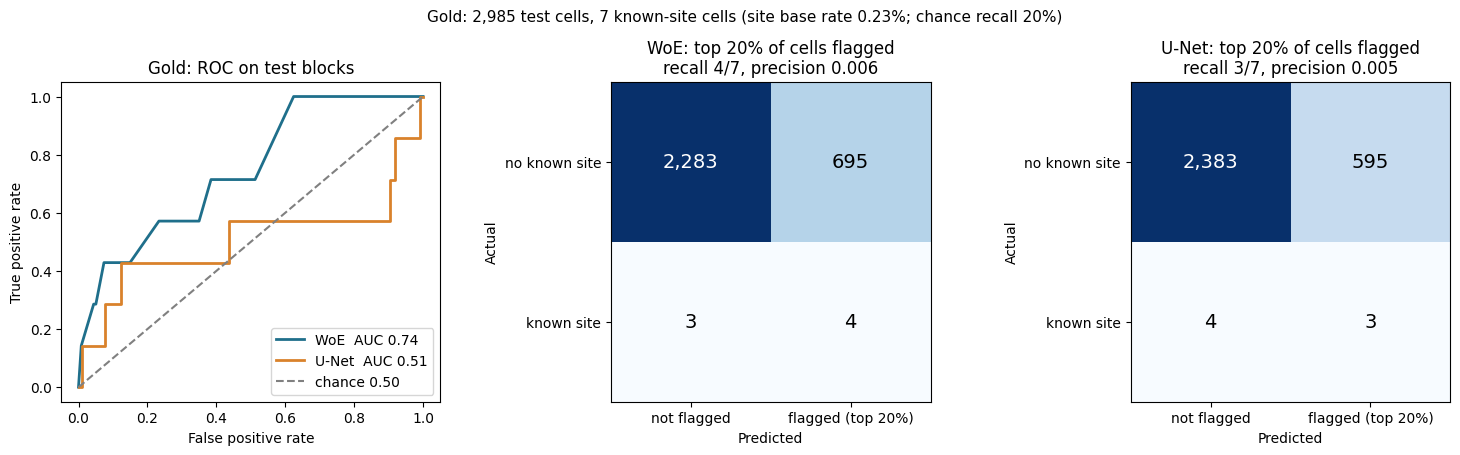

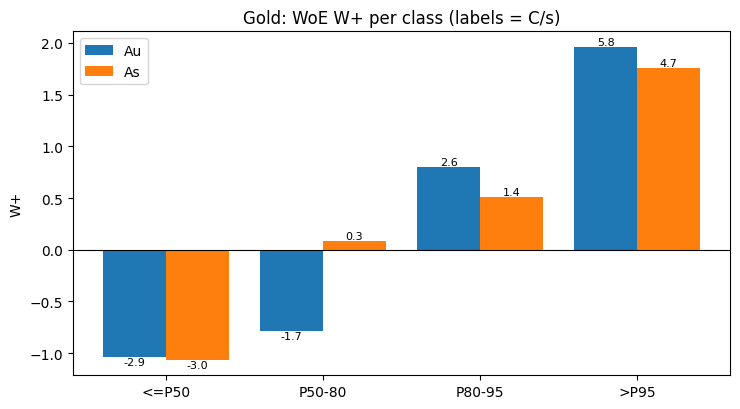

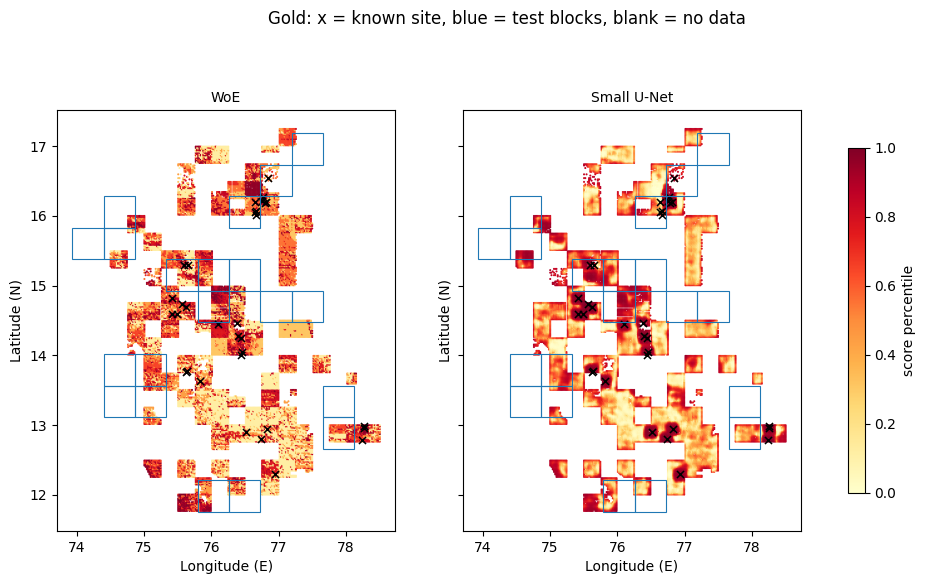

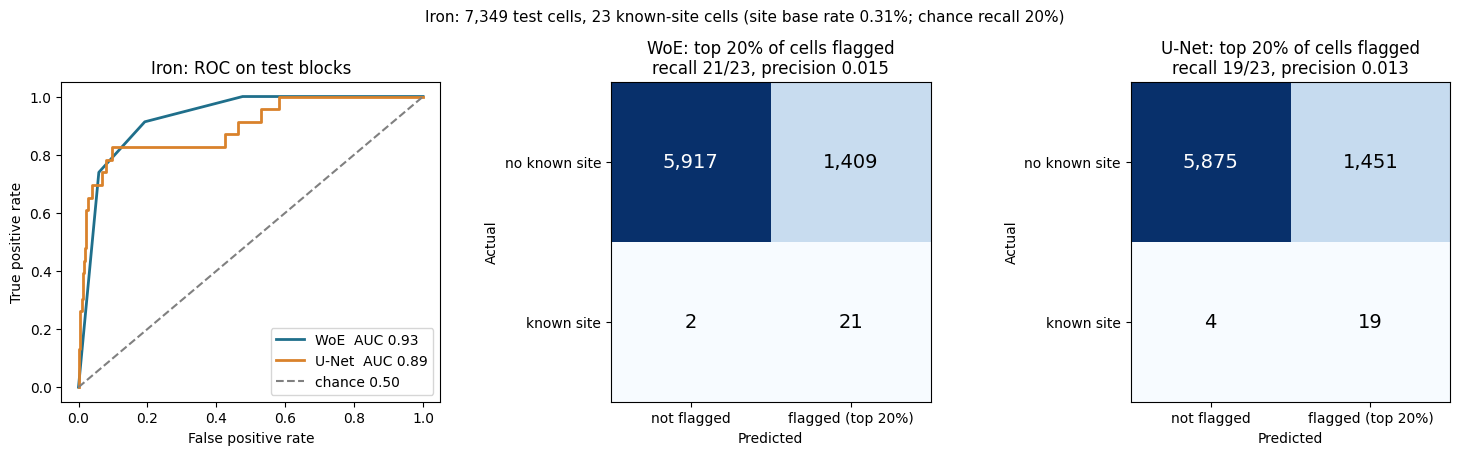

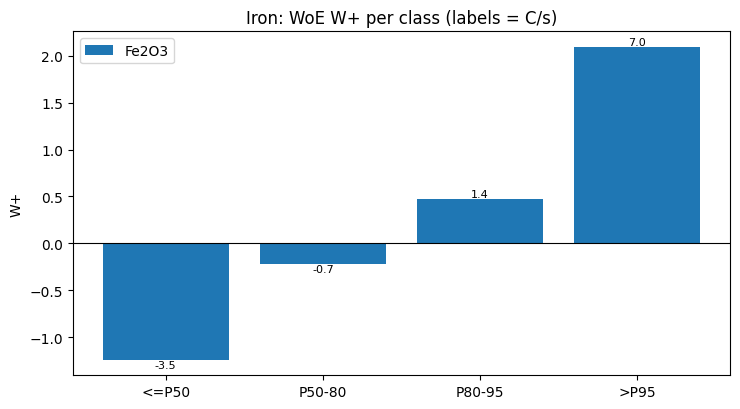

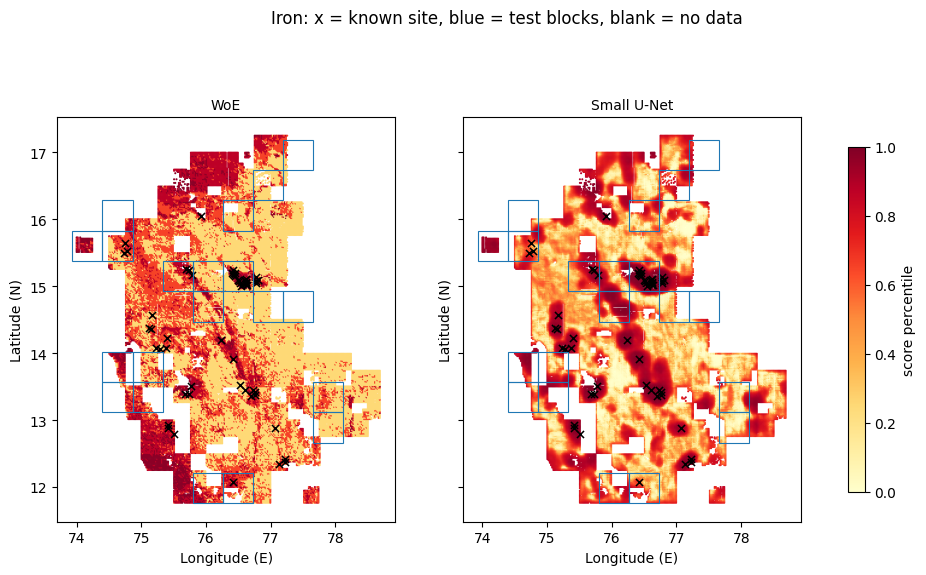

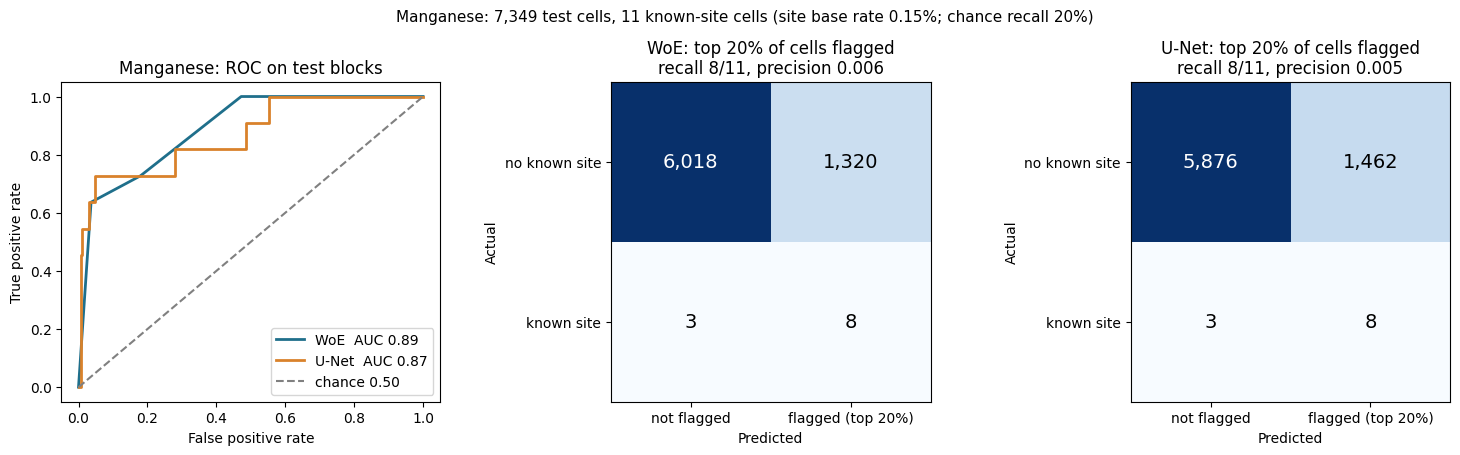

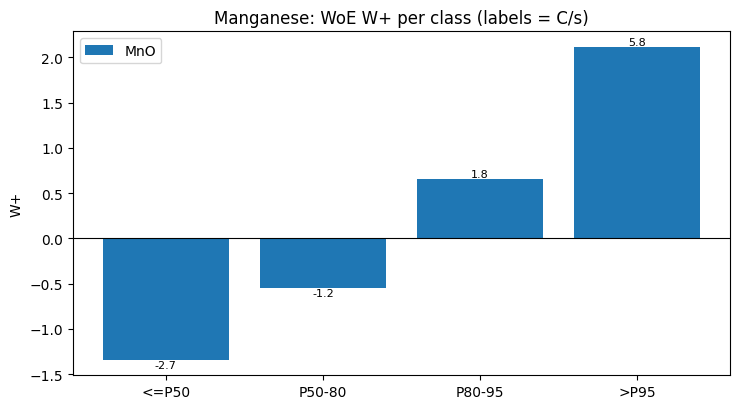

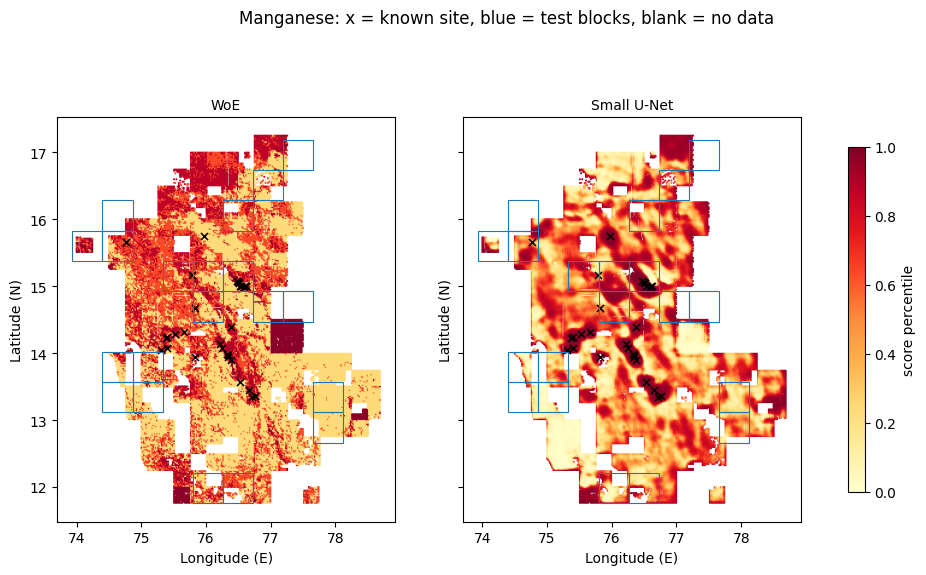

commodity,model,test_sites,sites_in_top20,recall,precision,AUC
gold,WoE,7,4,0.57,0.006,0.74
gold,U-Net,7,3,0.43,0.005,0.51
iron,WoE,23,21,0.91,0.015,0.93
iron,U-Net,23,19,0.83,0.013,0.89
manganese,WoE,11,8,0.73,0.006,0.89
manganese,U-Net,11,8,0.73,0.005,0.87


In [8]:
import sys, numpy as np, pandas as pd, matplotlib
sys.path.insert(0, ".")
import geominer_woe_rf as g, geominer_unet_planc as u, demo_woe as d
try: matplotlib.use("module://matplotlib_inline.backend_inline")   # demo_woe forces Agg; switch back for notebooks
except Exception: pass
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from IPython.display import display

ONLY = ["gold", "iron", "manganese"]      # e.g. ["gold"] for a faster run
STEPS, SEEDS, DILATE = 150, 3, 3          # reported U-Net setting
C_W, C_U = "#1f6f8b", "#d9822b"           # WoE / U-Net colours

stream = g.load_stream(g.find(DATA, "*Stream_Sediments*.kmz"))
mn = g.load_minerals(g.find(DATA, "*Minerals_Kar*.kml"))
tables = {n: g.prepare(n, j, stream, mn) for n, j in g.JOBS.items()}
chosen, _ = g.choose_test_blocks(tables)

summary = []
for name in ONLY:
    c, keys, layers = tables[name], u.KEYS[name], d.REF[name]
    test = np.array([(bx, by) in chosen for bx, by in zip(c.bx, c.by)])
    dev, te = np.where(~test)[0], np.where(test)[0]
    y = c.pos.values[te]

    woe_pct, wm = d.woe_eval(c, layers, test)                     # WoE: edges/scores from dev cells only
    R = u.Raster(c, keys, ~test)                                  # U-Net: trained on dev blocks only
    lg = np.zeros(len(c))
    for s in range(SEEDS):
        lg += u.predict(u.train_model(R, ~test, STEPS, 12, 9000 + s, DILATE, 100.0), R)
    unet_pct = pd.Series(lg).rank(pct=True).values
    scores = {"WoE": pd.Series(woe_pct[te]).rank(pct=True).values,
              "U-Net": pd.Series(unet_pct[te]).rank(pct=True).values}

    # ---- Figure 1: ROC + confusion matrices (top-20% cut) ----
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
    for k, col in (("WoE", C_W), ("U-Net", C_U)):
        fpr, tpr, _ = roc_curve(y, scores[k])
        ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{k}  AUC {roc_auc_score(y, scores[k]):.2f}")
    ax[0].plot([0, 1], [0, 1], "--", color="grey", label="chance 0.50")
    ax[0].set(title=f"{name.capitalize()}: ROC on test blocks", xlabel="False positive rate", ylabel="True positive rate")
    ax[0].legend(loc="lower right")
    for a, k in zip(ax[1:], ("WoE", "U-Net")):
        cm = confusion_matrix(y, (scores[k] >= 0.8).astype(int), labels=[0, 1])
        a.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                       color="white" if cm[i, j] > cm.max() / 2 else "black")
        tp, fn, fp = cm[1, 1], cm[1, 0], cm[0, 1]
        a.set(title=f"{k}: top 20% of cells flagged\nrecall {tp}/{tp+fn}, precision {tp/max(tp+fp,1):.3f}",
              xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged (top 20%)"],
              yticklabels=["no known site", "known site"], xlabel="Predicted", ylabel="Actual")
    fig.suptitle(f"{name.capitalize()}: {len(te):,} test cells, {int(y.sum())} known-site cells "
                 f"(site base rate {y.mean():.2%}; chance recall 20%)", fontsize=11)
    fig.tight_layout(); plt.show()

    # ---- Figure 2: WoE evidence per concentration class ----
    g.classify(c, layers, ref=c.iloc[dev])
    fig, ax = plt.subplots(figsize=(7.5, 4.2)); w = 0.8 / len(layers)
    for i, e in enumerate(layers):
        t = g.woe_table(c, e, dev)
        ax.bar(np.arange(4) + i * w, t["W+"], w, label=d.NICE[e])
        for j, v in enumerate(t["C/s"]):
            ax.text(j + i * w, t["W+"].iloc[j], f"{v:.1f}", ha="center",
                    va="bottom" if t["W+"].iloc[j] >= 0 else "top", fontsize=8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(np.arange(4) + w * (len(layers) - 1) / 2); ax.set_xticklabels(["<=P50", "P50-80", "P80-95", ">P95"])
    ax.set(title=f"{name.capitalize()}: WoE W+ per class (labels = C/s)", ylabel="W+"); ax.legend()
    fig.tight_layout(); plt.show()

    # ---- Figure 3: maps ----
    fig, ax = plt.subplots(1, 2, figsize=(12, 6.4), sharey=True)
    d.draw_map(ax[0], c, woe_pct, chosen, "WoE")
    sc = d.draw_map(ax[1], c, unet_pct, chosen, "Small U-Net")
    fig.colorbar(sc, ax=ax, shrink=0.7, label="score percentile")
    fig.suptitle(f"{name.capitalize()}: x = known site, blue = test blocks, blank = no data")
    plt.show()

    for k in ("WoE", "U-Net"):
        pred = scores[k] >= 0.8
        summary.append(dict(commodity=name, model=k, test_sites=int(y.sum()),
                            sites_in_top20=int((pred & (y == 1)).sum()),
                            recall=(pred & (y == 1)).sum() / y.sum(),
                            precision=(pred & (y == 1)).sum() / max(pred.sum(), 1),
                            AUC=roc_auc_score(y, scores[k])))

S = pd.DataFrame(summary)
display(S.style.format({"recall": "{:.2f}", "precision": "{:.3f}", "AUC": "{:.2f}"})
        .background_gradient(subset=["AUC"], cmap="Blues", vmin=0.4, vmax=1.0).hide(axis="index"))

## Comparison table: WoE (baseline) vs U-Net

,Test sites,WoE: sites in top 20%,U-Net: sites in top 20%,WoE recall,U-Net recall,WoE AUC,U-Net AUC,AUC diff (U-Net - WoE),Better on AUC
Commodity,,,,,,,,,
Gold,7,4/7,3/7,0.57,0.43,0.74,0.51,-0.24,WoE
Iron,23,21/23,19/23,0.91,0.83,0.93,0.89,-0.03,WoE
Manganese,11,8/11,8/11,0.73,0.73,0.89,0.87,-0.02,WoE


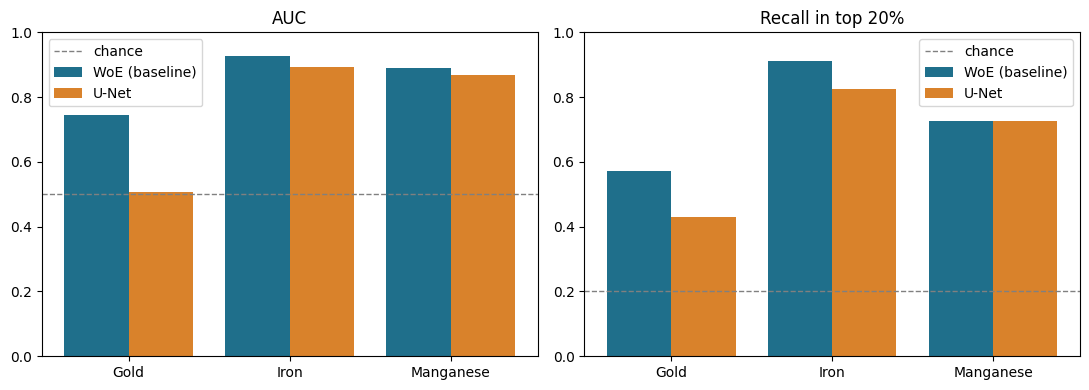

In [9]:
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
w = S[S.model == "WoE"].set_index("commodity")
n = S[S.model == "U-Net"].set_index("commodity")
T = pd.DataFrame({
    "Test sites": w["test_sites"],
    "WoE: sites in top 20%": w["sites_in_top20"].astype(str) + "/" + w["test_sites"].astype(str),
    "U-Net: sites in top 20%": n["sites_in_top20"].astype(str) + "/" + n["test_sites"].astype(str),
    "WoE recall": w["recall"], "U-Net recall": n["recall"],
    "WoE AUC": w["AUC"], "U-Net AUC": n["AUC"],
    "AUC diff (U-Net - WoE)": n["AUC"] - w["AUC"]})
T["Better on AUC"] = ["WoE" if x < -0.02 else "U-Net" if x > 0.02 else "Comparable" for x in T["AUC diff (U-Net - WoE)"]]
T.index = T.index.str.capitalize(); T.index.name = "Commodity"
display(T.style.format({"WoE recall": "{:.2f}", "U-Net recall": "{:.2f}", "WoE AUC": "{:.2f}",
                        "U-Net AUC": "{:.2f}", "AUC diff (U-Net - WoE)": "{:+.2f}"})
        .background_gradient(subset=["WoE AUC", "U-Net AUC"], cmap="Blues", vmin=0.4, vmax=1.0)
        .set_caption("Test blocks, scored once. Chance: recall 0.20, AUC 0.50. Few test sites: differences under ~0.05 AUC are noise."))
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); x = range(len(T))
for a, (cw, cn, title) in zip(ax, [("WoE AUC", "U-Net AUC", "AUC"), ("WoE recall", "U-Net recall", "Recall in top 20%")]):
    a.bar([i - 0.2 for i in x], T[cw], 0.4, label="WoE (baseline)", color="#1f6f8b")
    a.bar([i + 0.2 for i in x], T[cn], 0.4, label="U-Net", color="#d9822b")
    a.axhline(0.5 if title == "AUC" else 0.2, color="grey", ls="--", lw=1, label="chance")
    a.set_xticks(list(x)); a.set_xticklabels(T.index); a.set_ylim(0, 1); a.set_title(title); a.legend()
fig.tight_layout(); plt.show()